# NBA Player Archetypes: K-means Validation and GMM Comparison

This notebook uses the PCA score file produced by the existing exploratory-data-analysis pipeline. The main model is **K-means with eight clusters**; alternative cluster counts and Gaussian mixture models are evaluated as diagnostics. The input data are loaded from relative `../../data/processed/reg-szn/` paths, so execute this notebook from `notebooks/archetypes/` in the repository.

Run the notebook from top to bottom with a fresh kernel to regenerate all outputs. Cluster numbers are arbitrary labels, not ordered rankings.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('../../data/processed/reg-szn/player_data_merged.csv')

In [ ]:
# Grab PCA from EDA
scores = pd.read_csv('../../data/processed/reg-szn/pca_scores.csv')
pc_cols = [c for c in scores.columns if c.startswith('PC')]
X_pca = scores[pc_cols]

In [1]:
X_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,3.670733,0.082389,-0.395738,-0.280578,-1.740097,0.820665,1.342012
1,7.031763,2.394129,1.373684,-1.905985,-1.639699,-3.206950,-0.107169
2,-0.011131,2.232917,-2.311258,1.683359,-0.871462,0.547814,1.129884
3,1.634274,-3.997898,-0.397903,-1.235645,-0.209925,0.172383,0.070190
4,0.280834,0.099853,-1.484714,1.159856,-0.198962,-0.545351,0.495961
...,...,...,...,...,...,...,...
374,-0.406636,-2.336681,0.432336,2.127659,-0.930996,2.317523,-1.140433
375,-0.769863,-2.228162,-0.793294,-1.923219,0.240698,1.760034,-1.328132
376,0.779452,-0.280726,0.174685,-0.831370,2.903064,0.551547,0.069285
377,0.320727,-2.926944,-1.224661,-0.091917,1.207270,-0.279087,-0.211325


K-means evaluation results:
 k   inertia  silhouette  min_cluster_size  max_cluster_size
 2 9058.3248      0.2914                81               298
 3 6867.3531      0.2589                60               201
 4 6174.7000      0.2011                57               164
 5 5626.8684      0.1742                46               100
 6 5211.0261      0.1805                41                93
 7 4855.9354      0.1757                35                76
 8 4577.7246      0.1797                19                70
 9 4406.8034      0.1653                21                61
10 4266.0142      0.1605                18                59
11 4122.7517      0.1513                20                51
12 4018.1700      0.1436                16                50

Best k by silhouette score: 2
Current project choice: k = 8


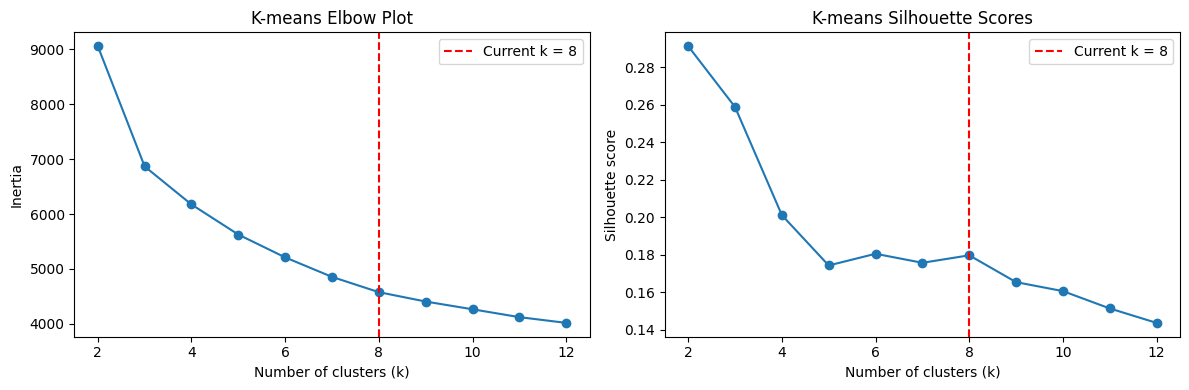

In [2]:
# ============================================================
# MODIFICATION 1: IMPROVED K-MEANS MODEL SELECTION
# ============================================================
# Goal:
# Compare possible numbers of clusters using multiple metrics
# rather than relying only on the elbow plot.
#
# We are NOT automatically changing k = 8.
# This section helps us determine whether k = 8 is justified.
# ============================================================

import numpy as np

# STEP 1: Define the candidate numbers of clusters.
# The original notebook tests k = 2 through 12.
ks = range(2, 13)

# Store evaluation results for each k.
results = []

# STEP 2: Fit a separate K-means model for each k.
for candidate_k in ks:

    model = KMeans(
        n_clusters=candidate_k,
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_pca)

    # Count how many players are assigned to each cluster.
    cluster_sizes = pd.Series(labels).value_counts()

    # STEP 3: Record model evaluation metrics.
    results.append({
        'k': candidate_k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X_pca, labels),
        'min_cluster_size': cluster_sizes.min(),
        'max_cluster_size': cluster_sizes.max()
    })

# STEP 4: Display a table of results.
results_df = pd.DataFrame(results)

print("K-means evaluation results:")
print(results_df.round(4).to_string(index=False))

# The highest silhouette score indicates the most separated
# clusters among the candidate k values.
best_k = int(
    results_df.loc[
        results_df['silhouette'].idxmax(), 'k'
    ]
)

print(f"\nBest k by silhouette score: {best_k}")
print("Current project choice: k = 8")

# STEP 5: Recreate the original evaluation plots.
# Elbow: look for diminishing improvements in inertia.
# Silhouette: higher scores indicate better separation.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    results_df['k'],
    results_df['inertia'],
    marker='o'
)
axes[0].axvline(8, color='red', linestyle='--',
                label='Current k = 8')
axes[0].set_title('K-means Elbow Plot')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(
    results_df['k'],
    results_df['silhouette'],
    marker='o'
)
axes[1].axvline(8, color='red', linestyle='--',
                label='Current k = 8')
axes[1].set_title('K-means Silhouette Scores')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].legend()

plt.tight_layout()
plt.show()


K-means cluster sizes:
KMeans_Cluster
0    70
1    46
2    19
3    67
4    36
5    39
6    52
7    50


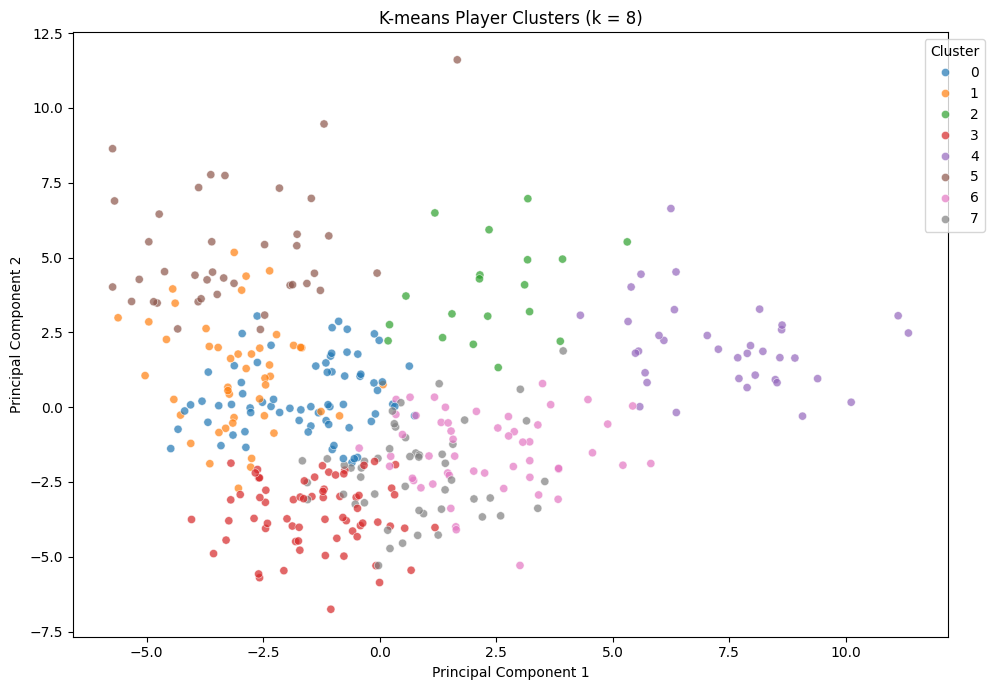


Cluster 0:
['Desmond Bane', 'Quentin Grimes', 'Miles Bridges', 'Jarace Walker', 'Brandin Podziemski', 'Cedric Coward', 'Jaden Ivey', 'Ayo Dosunmu']

Cluster 1:
['Ryan Rollins', 'Daniss Jenkins', 'Pat Spencer', 'Tyler Kolek', 'Walter Clayton', 'Scoot Henderson', 'Devin Carter', 'Dennis Schröder']

Cluster 2:
['Evan Mobley', 'Alex Sarr', 'Jaren Jackson Jr.', 'Domantas Sabonis', 'Kyle Filipowski', 'Derik Queen', 'Tristan Vukcevic', 'Alperen Şengün']

Cluster 3:
['Mohamed Diawara', 'Max Christie', 'Ben Sheppard', 'Toumani Camara', 'Taurean Prince', 'Svi Mykhailiuk', 'Tristan Da Silva', 'Cameron Johnson']

Cluster 4:
['Daniel Gafford', 'Neemias Queta', 'Jakob Poeltl', 'Goga Bitadze', 'Moussa Diabaté', 'Rudy Gobert', 'Marvin Bagley III', 'Clint Capela']

Cluster 5:
['Austin Reaves', 'Donovan Mitchell', 'Keyonte George', 'LeBron James', 'Julius Randle', 'Anthony Edwards', 'Shaedon Sharpe', 'Paolo Banchero']

Cluster 6:
['Jock Landale', 'Wendell Carter Jr.', 'Tidjane Salaün', 'Leonard Miller'

In [3]:

# ============================================================
# MODIFICATION 2: K-MEANS CLUSTERING AND REPRESENTATIVE PLAYERS
# ============================================================
# Purpose:
# 1. Fit our existing k = 8 model.
# 2. Preserve K-means labels separately from GMM labels.
# 3. Display cluster sizes and visualize assignments.
# 4. Identify players closest to each cluster centroid.
# ============================================================

import numpy as np

# STEP 1: Select the number of clusters.
# Keep k = 8 as our original baseline.
k = 8

# OPTIONAL: Uncomment to use the k with the highest
# silhouette score from Modification 1.
# k = best_k

# STEP 2: Fit K-means on the PCA-transformed data.
km = KMeans(
    n_clusters=k,
    n_init=20,
    random_state=42
)

scores['KMeans_Cluster'] = km.fit_predict(X_pca)

# STEP 3: Count players assigned to each cluster.
cluster_sizes = (
    scores['KMeans_Cluster']
    .value_counts()
    .sort_index()
)

print("K-means cluster sizes:")
print(cluster_sizes.to_string())

# STEP 4: Plot player assignments using PC1 and PC2.
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=scores,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='tab10',
    s=35,
    alpha=0.7
)

plt.title(f'K-means Player Clusters (k = {k})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# STEP 5: Calculate each player's distance to its centroid.
# Smaller distances indicate more representative players.
distances = km.transform(X_pca)

scores['Distance_to_Centroid'] = distances[
    np.arange(len(scores)),
    scores['KMeans_Cluster'].to_numpy()
]

# STEP 6: Print the eight closest players in each cluster.
for cluster, group in scores.groupby('KMeans_Cluster'):

    representatives = (
        group.sort_values('Distance_to_Centroid')
        ['Player']
        .head(8)
        .tolist()
    )

    print(f"\nCluster {cluster}:")
    print(representatives)


Average player statistics by cluster:
                per-100-possessions_PTS  per-100-possessions_3PA  per-100-possessions_AST  per-100-possessions_ORB  per-100-possessions_DRB  per-100-possessions_STL  per-100-possessions_BLK  per-100-possessions_TOV  advanced_USG%  advanced_TS%
KMeans_Cluster                                                                                                                                                                                                                                     
0                                 25.83                     8.70                     5.23                     1.56                     5.67                     1.52                     0.65                     2.74          22.11          0.57
1                                 21.39                     8.08                     9.10                     1.27                     5.28                     1.94                     0.55                     3.86          20.79 

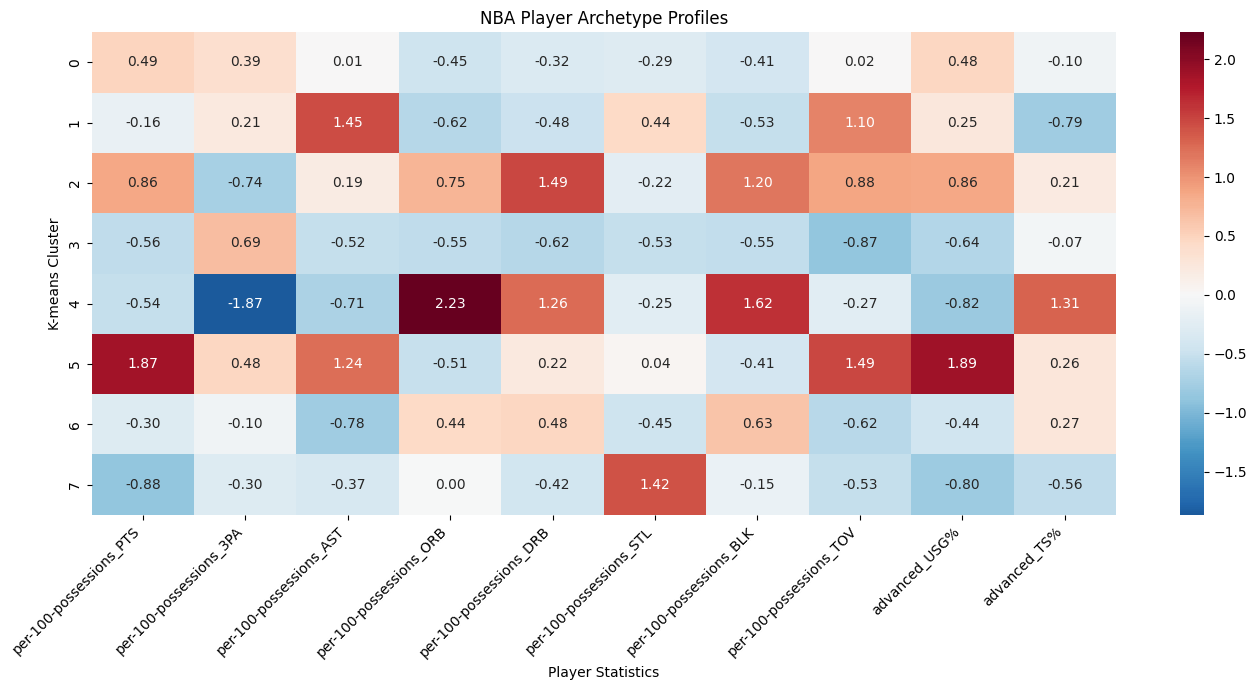


Cluster 0:
  per-100-possessions_PTS: +0.49 SD
  advanced_USG%: +0.48 SD
  per-100-possessions_ORB: -0.45 SD
  per-100-possessions_BLK: -0.41 SD

Cluster 1:
  per-100-possessions_AST: +1.45 SD
  per-100-possessions_TOV: +1.10 SD
  advanced_TS%: -0.79 SD
  per-100-possessions_ORB: -0.62 SD

Cluster 2:
  per-100-possessions_DRB: +1.49 SD
  per-100-possessions_BLK: +1.20 SD
  per-100-possessions_TOV: +0.88 SD
  advanced_USG%: +0.86 SD

Cluster 3:
  per-100-possessions_TOV: -0.87 SD
  per-100-possessions_3PA: +0.69 SD
  advanced_USG%: -0.64 SD
  per-100-possessions_DRB: -0.62 SD

Cluster 4:
  per-100-possessions_ORB: +2.23 SD
  per-100-possessions_3PA: -1.87 SD
  per-100-possessions_BLK: +1.62 SD
  advanced_TS%: +1.31 SD

Cluster 5:
  advanced_USG%: +1.89 SD
  per-100-possessions_PTS: +1.87 SD
  per-100-possessions_TOV: +1.49 SD
  per-100-possessions_AST: +1.24 SD

Cluster 6:
  per-100-possessions_AST: -0.78 SD
  per-100-possessions_BLK: +0.63 SD
  per-100-possessions_TOV: -0.62 SD
  per-

In [4]:

# ============================================================
# MODIFICATION 3: INTERPRETING PLAYER ARCHETYPES
# ============================================================
# Purpose:
# Use original NBA statistics to understand the
# characteristics of each K-means cluster.
#
# PCA is useful for clustering, but original statistics
# are easier to interpret in basketball terms.
# ============================================================

# STEP 1: Select relevant basketball statistics.
profile_features = [
    'per-100-possessions_PTS',
    'per-100-possessions_3PA',
    'per-100-possessions_AST',
    'per-100-possessions_ORB',
    'per-100-possessions_DRB',
    'per-100-possessions_STL',
    'per-100-possessions_BLK',
    'per-100-possessions_TOV',
    'advanced_USG%',
    'advanced_TS%'
]

# STEP 2: Check that the selected features exist.
missing_features = [
    col for col in profile_features if col not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing columns in merged dataset: {missing_features}"
    )

# STEP 3: Match the player eligibility rule used in PCA.
# The existing PCA notebook uses 500 total minutes.
eligible_players = df.loc[
    df['advanced_MP'] >= 500,
    ['Player'] + profile_features
].copy()

# Check that player names uniquely identify rows.
if eligible_players['Player'].duplicated().any():
    raise ValueError(
        "Duplicate player names in merged data. "
        "Inspect player identifiers before merging."
    )

if scores['Player'].duplicated().any():
    raise ValueError(
        "Duplicate player names in PCA scores."
    )

# STEP 4: Join K-means assignments to original statistics.
cluster_data = scores[
    ['Player', 'KMeans_Cluster']
].merge(
    eligible_players,
    on='Player',
    how='left',
    validate='one_to_one',
    indicator=True
)

# Confirm that all PCA players matched the source data.
unmatched = cluster_data.loc[
    cluster_data['_merge'] != 'both', 'Player'
]

if not unmatched.empty:
    raise ValueError(
        f"Unmatched players: {unmatched.tolist()[:20]}"
    )

cluster_data = cluster_data.drop(columns='_merge')

# STEP 5: Convert profile columns to numeric values.
cluster_data[profile_features] = cluster_data[
    profile_features
].apply(pd.to_numeric, errors='coerce')

# STEP 6: Calculate the average statistic for each cluster.
cluster_profiles = (
    cluster_data.groupby('KMeans_Cluster')[profile_features]
    .mean()
)

print("Average player statistics by cluster:")
print(cluster_profiles.round(2).to_string())

# STEP 7: Standardize for easier comparison across features.
# A positive value means above the sample average.
# A negative value means below the sample average.
feature_means = cluster_data[profile_features].mean()
feature_stds = cluster_data[profile_features].std(ddof=0)

cluster_profiles_z = (
    (cluster_profiles - feature_means)
    / feature_stds.replace(0, np.nan)
)

# STEP 8: Plot a heatmap of cluster characteristics.
plt.figure(figsize=(14, 7))

sns.heatmap(
    cluster_profiles_z,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0
)

plt.title('NBA Player Archetype Profiles')
plt.xlabel('Player Statistics')
plt.ylabel('K-means Cluster')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# STEP 9: Print the four most distinctive statistics
# for each cluster.
for cluster in cluster_profiles_z.index:

    profile = cluster_profiles_z.loc[cluster].dropna()

    strongest_features = (
        profile.abs()
        .sort_values(ascending=False)
        .head(4)
        .index
    )

    print(f"\nCluster {cluster}:")
    for feature in strongest_features:
        print(f"  {feature}: {profile[feature]:+.2f} SD")

# OPTIONAL:
# After reviewing the profiles, create a Markdown cell
# assigning descriptive basketball archetype names.
#
# Examples might include:
# - Primary playmakers
# - Three-point specialists
# - Interior defenders
# - Versatile forwards
#
# These are examples, NOT predetermined cluster labels.


Number of clusters: 8
Number of runs: 20
Mean ARI: 0.9253
Minimum ARI: 0.8605
Maximum ARI: 0.9950


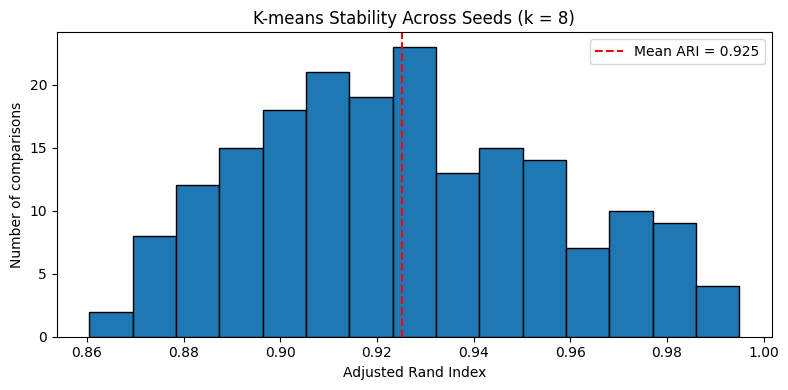

In [5]:

# ============================================================
# MODIFICATION 4: K-MEANS CLUSTER STABILITY ANALYSIS
# ============================================================
# Purpose:
# Determine whether K-means produces similar player
# assignments when using different random seeds.
#
# Adjusted Rand Index (ARI):
# 1.0 = identical partitions (ignoring cluster label names)
# 0.0 = agreement comparable to chance
#
# We compare assignments from repeated K-means runs.
# ============================================================

from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# STEP 1: Define random seeds.
# We test 20 different initializations.
seeds = range(20)

# STEP 2: Fit K-means separately for each seed.
all_labels = []

for seed in seeds:

    test_model = KMeans(
        n_clusters=km.n_clusters,
        n_init=20,
        random_state=seed
    )

    labels = test_model.fit_predict(X_pca)
    all_labels.append(labels)

# STEP 3: Compare every pair of cluster assignments.
ari_scores = []

for labels_a, labels_b in combinations(all_labels, 2):

    ari = adjusted_rand_score(labels_a, labels_b)
    ari_scores.append(ari)

# STEP 4: Summarize stability.
print(f"Number of clusters: {km.n_clusters}")
print(f"Number of runs: {len(all_labels)}")
print(f"Mean ARI: {np.mean(ari_scores):.4f}")
print(f"Minimum ARI: {np.min(ari_scores):.4f}")
print(f"Maximum ARI: {np.max(ari_scores):.4f}")

# STEP 5: Visualize stability.
plt.figure(figsize=(8, 4))

plt.hist(
    ari_scores,
    bins=15,
    edgecolor='black'
)

plt.axvline(
    np.mean(ari_scores),
    color='red',
    linestyle='--',
    label=f"Mean ARI = {np.mean(ari_scores):.3f}"
)

plt.title(f'K-means Stability Across Seeds (k = {km.n_clusters})')
plt.xlabel('Adjusted Rand Index')
plt.ylabel('Number of comparisons')
plt.legend()
plt.tight_layout()
plt.show()


In [6]:

# ============================================================
# K-MEANS CLUSTER SEPARATION ANALYSIS
# ============================================================
# Compare selected cluster pairs in PCA space.
#
# 1. Distance between centroids
# 2. Average distance of players to their own centroid
# 3. Average silhouette score within each cluster
#
# Larger centroid distances relative to within-cluster
# dispersion suggest better separation.
# ============================================================

from sklearn.metrics import silhouette_samples

# Calculate individual silhouette scores
player_silhouettes = silhouette_samples(
    X_pca,
    scores['KMeans_Cluster']
)

scores['Silhouette'] = player_silhouettes

# Calculate mean silhouette for each cluster
cluster_silhouettes = (
    scores.groupby('KMeans_Cluster')['Silhouette']
    .mean()
)

print("Mean silhouette score by cluster:")
print(cluster_silhouettes.round(4))

# Compare the two pairs of interest
cluster_pairs = [(0, 5), (2, 6)]

for a, b in cluster_pairs:

    # Distance between cluster centroids in PCA space
    centroid_distance = np.linalg.norm(
        km.cluster_centers_[a] - km.cluster_centers_[b]
    )

    # Average player distance to its own centroid
    avg_distance_a = scores.loc[
        scores['KMeans_Cluster'] == a,
        'Distance_to_Centroid'
    ].mean()

    avg_distance_b = scores.loc[
        scores['KMeans_Cluster'] == b,
        'Distance_to_Centroid'
    ].mean()

    # Descriptive separation ratio
    avg_within_distance = (
        avg_distance_a + avg_distance_b
    ) / 2

    separation_ratio = (
        centroid_distance / avg_within_distance
    )

    print(f"\nCluster {a} vs Cluster {b}")
    print(f"Centroid distance: {centroid_distance:.4f}")
    print(f"Average within-cluster distance: "
          f"{avg_within_distance:.4f}")
    print(f"Separation ratio: {separation_ratio:.4f}")

    print(f"Cluster {a} silhouette: "
          f"{cluster_silhouettes[a]:.4f}")
    print(f"Cluster {b} silhouette: "
          f"{cluster_silhouettes[b]:.4f}")


Mean silhouette score by cluster:
KMeans_Cluster
0    0.1667
1    0.1321
2    0.1247
3    0.2371
4    0.2578
5    0.1508
6    0.1728
7    0.1589
Name: Silhouette, dtype: float64

Cluster 0 vs Cluster 5
Centroid distance: 5.2270
Average within-cluster distance: 3.4756
Separation ratio: 1.5039
Cluster 0 silhouette: 0.1667
Cluster 5 silhouette: 0.1508

Cluster 2 vs Cluster 6
Centroid distance: 5.4815
Average within-cluster distance: 3.5401
Separation ratio: 1.5484
Cluster 2 silhouette: 0.1247
Cluster 6 silhouette: 0.1728


Pairwise centroid distances:
       0       1      2       3       4       5      6      7
0  0.000   4.128  5.757   4.050   9.362   5.227  4.544  4.779
1  4.128   0.000  7.107   6.161  10.798   5.679  7.049  5.762
2  5.757   7.107  0.000   8.587   6.135   6.045  5.482  7.155
3  4.050   6.161  8.587   0.000  10.524   8.985  4.384  4.381
4  9.362  10.798  6.135  10.524   0.000  11.212  6.605  8.460
5  5.227   5.679  6.045   8.985  11.212   0.000  8.706  8.925
6  4.544   7.049  5.482   4.384   6.605   8.706  0.000  3.871
7  4.779   5.762  7.155   4.381   8.460   8.925  3.871  0.000


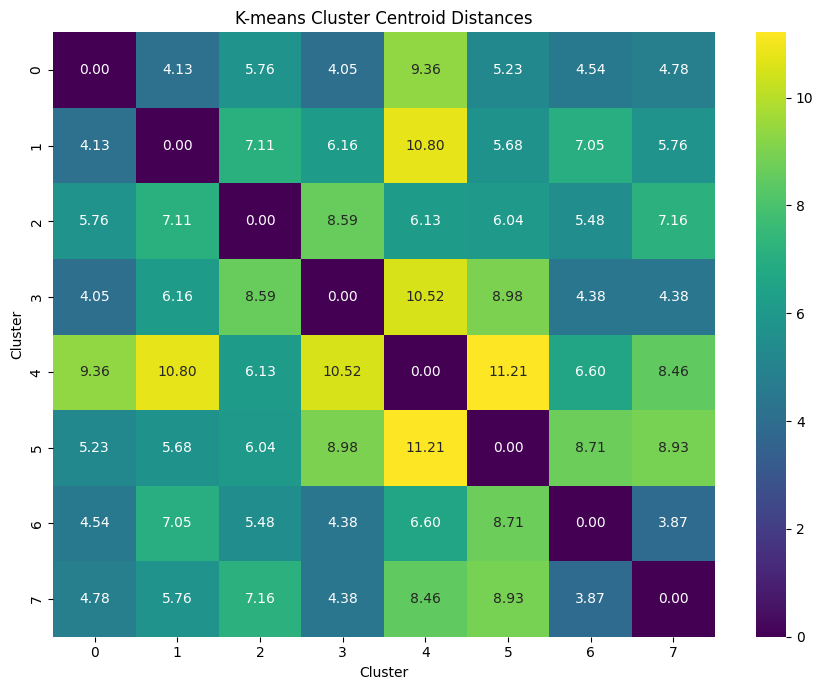


Nearest neighbor for each cluster:
Cluster 0 -> Cluster 3 (distance = 4.0499)
Cluster 1 -> Cluster 0 (distance = 4.1284)
Cluster 2 -> Cluster 6 (distance = 5.4815)
Cluster 3 -> Cluster 0 (distance = 4.0499)
Cluster 4 -> Cluster 2 (distance = 6.1346)
Cluster 5 -> Cluster 0 (distance = 5.2270)
Cluster 6 -> Cluster 7 (distance = 3.8712)
Cluster 7 -> Cluster 6 (distance = 3.8712)


In [7]:
# ============================================================
# ALL-CLUSTER CENTROID DISTANCE ANALYSIS
# ============================================================
# Identify which K-means clusters are closest in PCA space.
# This helps detect potentially redundant player archetypes.
# ============================================================

from sklearn.metrics import pairwise_distances

# STEP 1: Compute Euclidean distances between all centroids
centroid_distances = pairwise_distances(
    km.cluster_centers_,
    metric='euclidean'
)

# STEP 2: Determine the number of clusters directly from the fitted model
n_clusters = km.n_clusters

distance_df = pd.DataFrame(
    centroid_distances,
    index=range(n_clusters),
    columns=range(n_clusters)
)

print("Pairwise centroid distances:")
print(distance_df.round(3))

# STEP 3: Visualize the distance matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    distance_df,
    annot=True,
    fmt='.2f',
    cmap='viridis'
)

plt.title('K-means Cluster Centroid Distances')
plt.xlabel('Cluster')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

# STEP 4: Identify the closest neighboring cluster
# Exclude self-distances along the diagonal
distances_no_self = distance_df.copy()
np.fill_diagonal(distances_no_self.values, np.inf)

print("\nNearest neighbor for each cluster:")

for cluster in distance_df.index:
    nearest = distances_no_self.loc[cluster].idxmin()
    distance = distances_no_self.loc[cluster, nearest]

    print(
        f"Cluster {cluster} -> Cluster {nearest} "
        f"(distance = {distance:.4f})"
    )

In [8]:
# Compare k = 6 against our original k = 8 model

km6 = KMeans(
    n_clusters=6,
    n_init=20,
    random_state=42
)

scores['KMeans_Cluster_6'] = km6.fit_predict(X_pca)

# Silhouette comparison
sil6 = silhouette_score(
    X_pca,
    scores['KMeans_Cluster_6']
)

sil8 = silhouette_score(
    X_pca,
    scores['KMeans_Cluster']
)

print(f"Silhouette (k=6): {sil6:.4f}")
print(f"Silhouette (k=8): {sil8:.4f}")

# Compare assignments between the two solutions
ari_6_vs_8 = adjusted_rand_score(
    scores['KMeans_Cluster_6'],
    scores['KMeans_Cluster']
)

print(f"ARI (k=6 vs k=8): {ari_6_vs_8:.4f}")

# Show which k=8 clusters are reassigned to k=6 clusters
comparison = pd.crosstab(
    scores['KMeans_Cluster'],
    scores['KMeans_Cluster_6']
)

print("\nCluster assignment comparison:")
print(comparison)

Silhouette (k=6): 0.1805
Silhouette (k=8): 0.1797
ARI (k=6 vs k=8): 0.5513

Cluster assignment comparison:
KMeans_Cluster_6   0   1   2   3   4   5
KMeans_Cluster                          
0                 18   5  16   0  31   0
1                  0   2   0   0  44   0
2                  0   2  14   3   0   0
3                 66   0   0   0   0   1
4                  0   0   0  36   0   0
5                  0  39   0   0   0   0
6                  7   0  29   2   0  14
7                  2   0   0   0   0  48


Models evaluated: 44

BIC values:
cov      diag      full  spherical      tied
k                                           
2    10660.42  10755.74   11173.98  10748.30
3    10636.60  10745.92   10831.53  10747.01
4    10639.80  10844.00   10798.07  10688.81
5    10636.69  10958.79   10744.86  10728.36
6    10647.89  11112.32   10721.88  10681.48
7    10675.88  11256.32   10704.24  10690.47
8    10740.01  11390.63   10696.23  10700.79
9    10783.72  11535.73   10721.42  10726.19
10   10839.94  11681.29   10731.42  10772.13
11   10897.57  11676.36   10753.84  10790.00
12   10951.59  11960.61   10783.83  10794.73


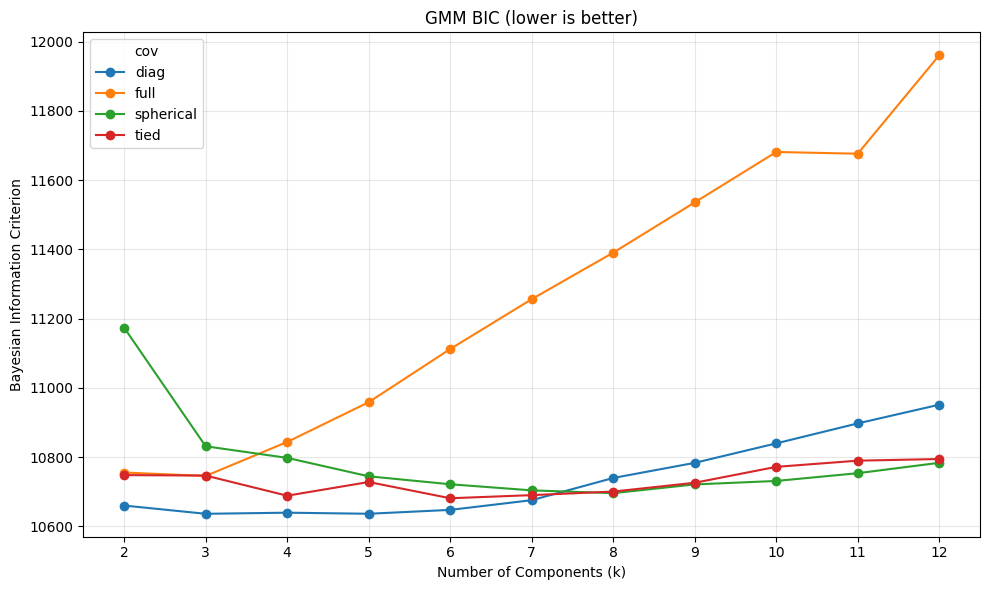


Best GMM component count: 3
Best covariance type: diag
Minimum BIC: 10636.60


In [9]:

from sklearn.mixture import GaussianMixture

# ============================================================
# GMM MODEL SELECTION USING BIC
# ============================================================
# Test four covariance structures and 2-12 components.
# Lower BIC indicates a preferred model among those tested.
#
# Use n_components rather than k so we do not overwrite
# the cluster count used in our K-means analysis.
# ============================================================

gmm_results = []

for cov in ['spherical', 'diag', 'tied', 'full']:
    for n_components in range(2, 13):

        # Fit a Gaussian Mixture Model
        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type=cov,
            n_init=5,
            random_state=42
        ).fit(X_pca)

        # IMPORTANT: This line stays inside BOTH loops.
        # Record the BIC for every model configuration.
        gmm_results.append({
            'cov': cov,
            'k': n_components,
            'bic': gmm.bic(X_pca)
        })

# STEP 1: Verify that all configurations were evaluated.
print(f"Models evaluated: {len(gmm_results)}")

assert len(gmm_results) == 44, (
    "Expected 44 GMM configurations. "
    "Check the indentation of results.append()."
)

# STEP 2: Create the BIC dataframe.
bic = pd.DataFrame(gmm_results).pivot(
    index='k',
    columns='cov',
    values='bic'
)

# Verify that every covariance type has 11 BIC values.
assert bic.shape == (11, 4), (
    f"Expected an 11x4 BIC table, got {bic.shape}."
)

print("\nBIC values:")
print(bic.round(2))

# STEP 3: Restore the ORIGINAL combined visualization.
ax = bic.plot(
    marker='o',
    figsize=(10, 6),
    title='GMM BIC (lower is better)'
)

ax.set_xlabel('Number of Components (k)')
ax.set_ylabel('Bayesian Information Criterion')
ax.set_xticks(range(2, 13))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# STEP 4: Identify the best model.
best_k, best_cov = bic.stack().idxmin()

print(f"\nBest GMM component count: {best_k}")
print(f"Best covariance type: {best_cov}")
print(f"Minimum BIC: {bic.loc[best_k, best_cov]:.2f}")


In [10]:

# ============================================================
# MODIFICATION 5: GMM CLUSTERING AND MODEL COMPARISON
# ============================================================
# Purpose:
# 1. Fit the BIC-selected GMM configuration.
# 2. Store GMM labels separately from K-means labels.
# 3. Evaluate membership confidence.
# 4. Compare GMM and K-means using ARI.
# ============================================================

# STEP 1: Fit the BIC-selected Gaussian Mixture Model.
# Component count and covariance type come from the preceding cell.
gmm = GaussianMixture(
    n_components=best_k,
    covariance_type=best_cov,
    n_init=10,
    random_state=42
).fit(X_pca)

# STEP 2: Calculate cluster membership probabilities.
probs = gmm.predict_proba(X_pca)

# STEP 3: Save GMM labels separately from K-means.
scores['GMM_Cluster'] = probs.argmax(axis=1)

# Confidence is the highest membership probability.
scores['GMM_Confidence'] = probs.max(axis=1)

# STEP 4: Summarize membership confidence.
print("GMM membership confidence by cluster:")

print(
    scores.groupby('GMM_Cluster')['GMM_Confidence']
    .describe()
)

# STEP 5: Display representative GMM players.
# Higher confidence indicates stronger membership
# under the fitted Gaussian mixture model.
for cluster, group in scores.groupby('GMM_Cluster'):

    representatives = (
        group.sort_values(
            'GMM_Confidence',
            ascending=False
        )['Player']
        .head(8)
        .tolist()
    )

    print(f"\nGMM Cluster {cluster}:")
    print(representatives)

# STEP 6: Compare GMM and K-means assignments.
comparison_ari = adjusted_rand_score(
    scores['KMeans_Cluster'],
    scores['GMM_Cluster']
)

print(f"\nK-means vs GMM ARI: {comparison_ari:.4f}")


GMM membership confidence by cluster:
             count      mean       std       min       25%       50%  \
GMM_Cluster                                                            
0             56.0  0.931650  0.136861  0.443276  0.955048  0.999023   
1            119.0  0.897350  0.131067  0.502413  0.846974  0.964632   
2            204.0  0.866953  0.146667  0.398906  0.782051  0.937550   

                  75%       max  
GMM_Cluster                      
0            0.999963  1.000000  
1            0.995980  0.999993  
2            0.978922  0.999718  

GMM Cluster 0:
['Jericho Sims', 'Mitchell Robinson', 'Luke Kornet', 'Ryan Kalkbrenner', 'Moussa Cisse', 'Yves Missi', 'Dwight Powell', 'Rudy Gobert']

GMM Cluster 1:
['Luka Dončić', 'Ja Morant', 'Cade Cunningham', 'Shai Gilgeous-Alexander', 'Jaylen Brown', 'Devin Booker', 'James Harden', 'Kawhi Leonard']

GMM Cluster 2:
['Spencer Jones', 'Hugo González', 'Kris Murray', 'Rasheer Fleming', 'Ryan Dunn', 'Ochai Agbaji', 'Derrick J

In [11]:
# Compare K-means and GMM using the same number of clusters

gmm8 = GaussianMixture(
    n_components=km.n_clusters,
    covariance_type='diag',
    n_init=10,
    random_state=42
).fit(X_pca)

scores['GMM_Cluster_8'] = gmm8.predict(X_pca)

ari_equal_k = adjusted_rand_score(
    scores['KMeans_Cluster'],
    scores['GMM_Cluster_8']
)

print(f"ARI: K-means (8) vs BIC-selected GMM = {comparison_ari:.4f}")
print(f"ARI: K-means (8) vs equal-component GMM = {ari_equal_k:.4f}")

ARI: K-means (8) vs GMM (3) = 0.2329
ARI: K-means (8) vs GMM (8) = 0.5887


## Summary of results and limitations

- **Reproducibility:** Eight-cluster K-means was consistent across 20 initialization seeds (mean pairwise adjusted Rand index **0.9253**, minimum **0.8605**). This measures **initialization stability**, not stability across seasons or new samples.
- **Separation:** The overall silhouette at **k = 8** was **0.1797**, indicating substantial overlap in PCA space. The highest silhouette among k = 2–12 was at **k = 2 (0.2914)**. The k = 6 silhouette was **0.1805**, nearly identical to k = 8, and the six- and eight-cluster partitions had ARI **0.5513**.
- **Interpretation:** Average per-100-possession and advanced statistics, standardized cluster profiles, and centroid-nearest player examples permit evidence-based archetype interpretation. Tentative categories include primary creators, playmakers, perimeter shooting specialists, traditional interior centers, and defensive-oriented role players. Names are exploratory and should be checked against full player lists and domain knowledge.
- **Redundancy checks:** Per-cluster silhouettes and centroid distances identify nearby or overlapping groups. Centroid proximity alone is not a basis for manually merging clusters.
- **Alternative model:** Among 44 tested GMM configurations, BIC selected **three components with diagonal covariance**. Agreement between K-means (8) and GMM (3) was ARI **0.2329**; agreement against an eight-component diagonal GMM was **0.5887**. The selected GMM and the equal-component GMM address different comparison questions.

**Modeling decision:** Retain k = 8 as a *provisional, interpretability-driven* player-archetype solution, **not** because it maximizes silhouette or is objectively optimal. The enhancements improve the evidence, reproducibility diagnostics, and readability of the analysis; they do **not** demonstrate a numerical improvement in K-means clustering quality. Next steps for the overall project are external validation and connecting player archetype composition to team performance.

In [ ]:
# ============================================================
# K-MEANS NOTEBOOK IMPROVEMENTS: SUMMARY
# ============================================================
# Compared with the original exploratory notebook, this version:
# 1. Evaluates k = 2-12 with inertia, silhouette, and cluster sizes.
# 2. Shows centroid-nearest representative players instead of the
#    first players in each cluster.
# 3. Profiles each cluster using original NBA statistics and a
#    standardized heatmap to interpret basketball archetypes.
# 4. Tests K-means initialization stability across 20 random seeds
#    using pairwise Adjusted Rand Index (mean ARI = 0.9253).
# 5. Examines per-cluster silhouettes and all centroid distances
#    to identify potentially overlapping archetypes.
# 6. Compares k = 6 and k = 8 using silhouette and player
#    reassignments (0.1805 vs. 0.1797; ARI = 0.5513).
# 7. Keeps K-means and GMM labels separate, selects the GMM
#    configuration using BIC, and compares model partitions.
#
# Conclusion:
# k = 8 remains a provisional choice for interpretable player
# archetypes. The analysis is now better validated, more
# reproducible, and easier to explain, but the silhouette score
# remains low (0.1797). We have NOT shown that model quality
# improved numerically or that k = 8 is objectively optimal.
# ============================================================